# Photos from the robot vs the golden model (R7)

Group 26, Wilson (M2). Every folder in `golden/framegrab/grabs/` is one JTAG photo: the 320 x 240 picture the board
kept, plus the 18 result words `vision_grab_results.sv` put with it, for that same frame. This notebook runs
`validate_grab.py` on each one and shows the evidence.

* **KEPT, exact.** A second `led_centroid` on the board saw only the photo's pixels, so `model.py` on the photo
  must give its numbers bit for bit: the real camera and the real FPGA, against the golden model.
* **FULL, approximate.** The robot's own `led_centroid` over all 640 x 480 pixels. Compared within a tolerance,
  because the photo holds only a quarter of those pixels.
* **Replay, exact.** The photo goes through the camera model and the robot's RTL in Verilator. Its KEPT words
  must equal the board's, and its FULL words must equal the model on the doubled photo.

Taking photos: `python golden/framegrab/tools/take_photo.py <name>` on the computer with the USB-Blaster
(`golden/framegrab/README.md`). The `sim_*` folders came from the simulated board (`framegrab_sim.py`); real
photos sit beside them.

In [1]:
import os, sys, json, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / 'golden' / 'framegrab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FG = ROOT / 'golden' / 'framegrab'
sys.path[:0] = [str(FG), str(ROOT / 'golden'), str(FG / 'vendor' / 'tools')]
import validate_grab as vg, model, grab as vgrab

# Verilator for the replay: on PATH, or Ed's / this machine's build
for d in ('/opt/vsrc/verilator/bin',):
    if Path(d, 'verilator').exists() and not shutil.which('verilator'):
        os.environ['PATH'] = d + os.pathsep + os.environ['PATH']
        os.environ.setdefault('VERILATOR_ROOT', str(Path(d).parent))
REPLAY = vg.have_verilator()
RUN_SIMULATED_BOARD = False      # True: run framegrab_sim.py first (about a minute, needs Verilator)
print('repo:', ROOT, '| replay:', 'yes' if REPLAY else 'no (no Verilator: KEPT and FULL checks only)')

repo: /home/claude/work | replay: yes


In [2]:
if RUN_SIMULATED_BOARD:
    import framegrab_sim
    framegrab_sim.main([])

## Every photo, every check

In [3]:
grabs = sorted(p.parent for p in (FG / 'grabs').glob('*/dump.bin'))
exe = vg.build_replay() if REPLAY else None
reports = {}
for g in grabs:
    reports[g.name] = vg.validate(g, replay=REPLAY, exe=exe, echo=False)
rows = []
for name, rep in reports.items():
    d = json.load(open(FG / 'grabs' / name / 'validation.json'))
    k, f = d['decoded']['kept'], d['decoded']['full']
    rows.append(dict(photo=name, SW1=d['sw1'], verdict='FAIL' if rep.fails else ('WARN' if rep.warns else 'PASS'),
                     fails=rep.fails, warns=rep.warns,
                     robot_valid=f['valid'], robot_x=f['x'] if f['valid'] else None, robot_y=f['y'] if f['valid'] else None,
                     robot_count=f['count'], robot_flags=vg.flag_text(f['flags']),
                     kept_count=k['count'], kept_conf=k['conf'], replay='yes' if d['replay_words'] else 'no'))
summary = pd.DataFrame(rows).set_index('photo')
summary

,SW1,verdict,fails,warns,robot_valid,robot_x,robot_y,robot_count,robot_flags,kept_count,kept_conf,replay
photo,,,,,,,,,,,,
sim_photo_leds_v2,0,PASS,0,0,1,430.0,204.0,321,none,79,183,yes
sim_two_red_v1,1,PASS,0,0,1,267.0,270.0,676,low_fill,167,3,yes
sim_two_red_v2,0,PASS,0,0,0,NaN,NaN,676,low_fill,167,3,yes


In [4]:
checks = pd.DataFrame([dict(photo=n, result=w, check=c, detail=t) for n, rep in reports.items() for w, c, t in rep.lines])
pd.set_option('display.max_colwidth', 160)
checks[checks.result != 'INFO'].pivot_table(index='check', columns='photo', values='result', aggfunc='first')

photo,sim_photo_leds_v2,sim_two_red_v1,sim_two_red_v2
check,,,
FULL (approximate),PASS,PASS,PASS
KEPT (exact),PASS,PASS,PASS
KEPT sums (exact),PASS,PASS,PASS
integrity,PASS,PASS,PASS
replay FULL == model on the doubled photo (exact),PASS,PASS,PASS
replay KEPT == board (exact),PASS,PASS,PASS
replay pixels,PASS,PASS,PASS


## The photos

Yellow + and box: the board's KEPT result. Cyan x: the model's KEPT (on top of the yellow when they agree). Green o:
the robot's own target (FULL), halved onto the photo. Right: the model's `red_mask` on the photo.

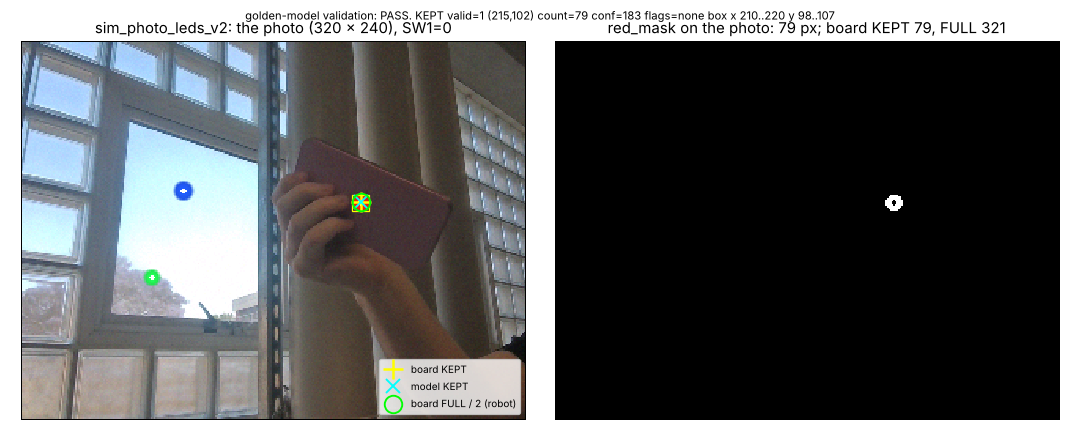

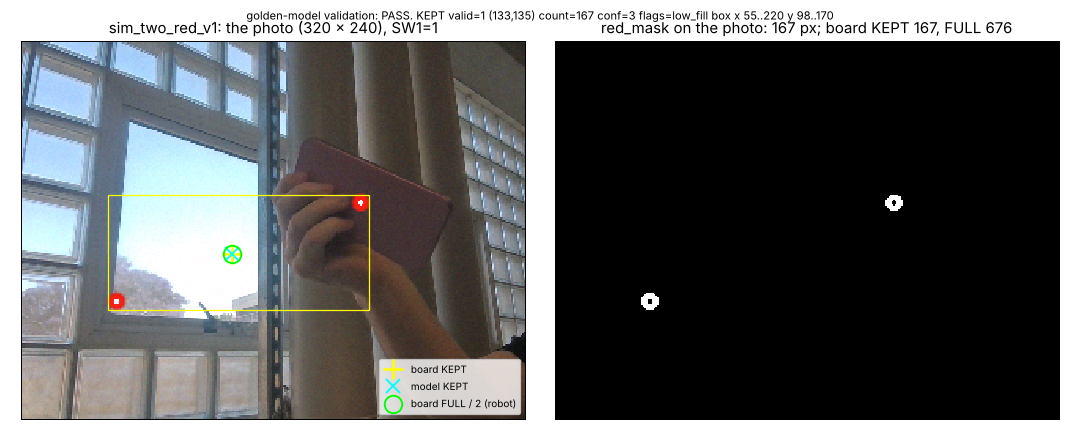

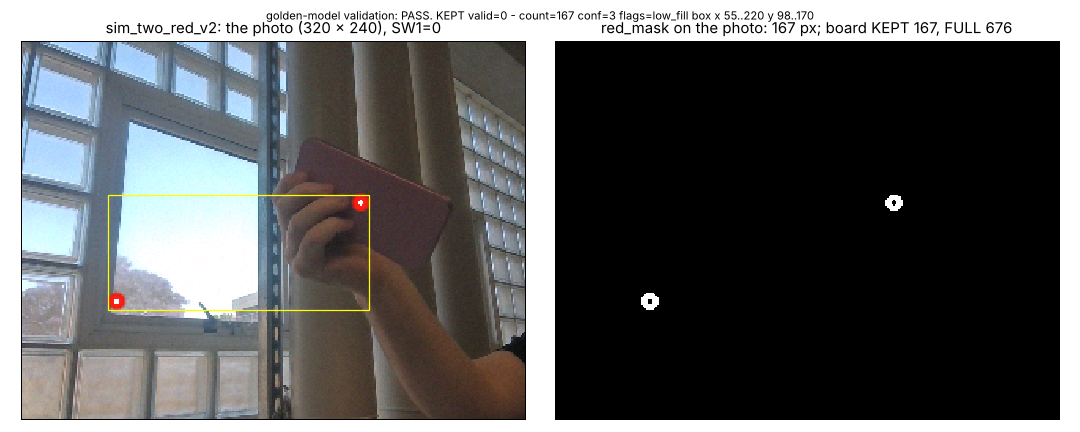

In [5]:
from IPython.display import Image, display
for g in grabs:
    if (g / 'validation.png').exists():
        display(Image(filename=str(g / 'validation.png')))

## Board vs model, number by number

The board's words next to the golden model's, for each photo. KEPT must be identical. FULL is next to the model on the
pixel-doubled photo (and the replay's FULL, which must equal that model).

In [6]:
def side_by_side(g):
    d = json.load(open(g / 'validation.json'))
    k, f = d['decoded']['kept'], d['decoded']['full']
    mk, mf = d['model_kept'], d['model_full_doubled']
    rep = vg.decode_words([int(w, 16) for w in d['replay_words']]) if d['replay_words'] else None
    keys = list(vg.RESULT_KEYS)
    t = pd.DataFrame({'board KEPT': [k[x] for x in keys], 'model KEPT': [mk[x] for x in keys],
                      'board FULL (robot)': [f[x] for x in keys], 'model FULL (doubled)': [mf[x] for x in keys]}, index=keys)
    if rep:
        t['replay FULL'] = [rep['full'][x] for x in keys]
        t['replay KEPT'] = [rep['kept'][x] for x in keys]
    return t
for g in grabs:
    print(g.name)
    display(side_by_side(g))

sim_photo_leds_v2


,board KEPT,model KEPT,board FULL (robot),model FULL (doubled),replay FULL,replay KEPT
valid,1,1,1,1,1,1
x,215,215,430,430,430,215
y,102,102,204,205,205,102
count,79,79,321,316,316,79
conf,183,183,186,183,183,183
flags,0,0,0,0,0,0
bx0,210,210,420,420,420,210
bx1,220,220,440,441,441,220
by0,98,98,195,196,196,98
by1,107,107,215,215,215,107


sim_two_red_v1


,board KEPT,model KEPT,board FULL (robot),model FULL (doubled),replay FULL,replay KEPT
valid,1,1,1,1,1,1
x,133,133,267,267,267,133
y,135,135,270,271,271,135
count,167,167,676,668,668,167
conf,3,3,3,3,3,3
flags,8,8,8,8,8,8
bx0,55,55,109,110,110,55
bx1,220,220,440,441,441,220
by0,98,98,195,196,196,98
by1,170,170,341,341,341,170


sim_two_red_v2


,board KEPT,model KEPT,board FULL (robot),model FULL (doubled),replay FULL,replay KEPT
valid,0,0,0,0,0,0
x,0,0,0,0,0,0
y,0,0,0,0,0,0
count,167,167,676,668,668,167
conf,3,3,3,3,3,3
flags,8,8,8,8,8,8
bx0,55,55,109,110,110,55
bx1,220,220,440,441,441,220
by0,98,98,195,196,196,98
by1,170,170,341,341,341,170


## Where the photo's pixels sit against the red thresholds

`red_mask` (V2 defaults, V1-equivalent): R5 >= RED_MIN, G6 <= RED_GREEN6_MAX, B5 <= RED_BLUE_MAX, and red beats
green and blue by RED_MARGIN. Each photo's pixels are plotted as red against green (5-bit), with the ones the mask
accepts in red. Real LEDs saturate to a white core and an orange halo, and this plot shows how much of the
blob sits near an edge. That is where tuning the thresholds would act.

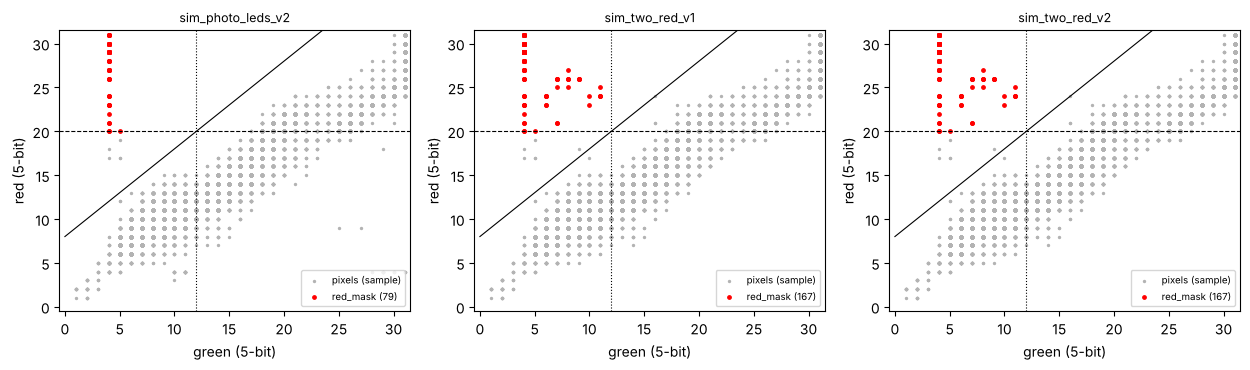

In [7]:
p = model.MaskParams()
fig, axes = plt.subplots(1, len(grabs), figsize=(4.2 * len(grabs), 3.8), squeeze=False)
for ax, g in zip(axes[0], grabs):
    info, frame = vg.load_grab(g)
    px = frame.ravel().astype(np.int64)
    r, g6, b = (px >> 11) & 31, (px >> 5) & 63, px & 31
    m = model.red_mask(frame.ravel(), p)
    sel = np.random.default_rng(0).choice(px.size, min(px.size, 20000), replace=False)
    ax.scatter(g6[sel] >> 1, r[sel], s=2, c='0.7', label='pixels (sample)')
    ax.scatter(g6[m] >> 1, r[m], s=6, c='red', label=f'red_mask ({int(m.sum())})')
    ax.axhline(p.RED_MIN, ls='--', c='k', lw=0.8); ax.axvline(p.RED_GREEN6_MAX / 2, ls=':', c='k', lw=0.8)
    gg = np.arange(0, 32); ax.plot(gg, gg + p.RED_MARGIN, c='k', lw=0.8)
    ax.set_xlim(-0.5, 31.5); ax.set_ylim(-0.5, 31.5); ax.set_xlabel('green (5-bit)'); ax.set_ylabel('red (5-bit)')
    ax.set_title(g.name, fontsize=9); ax.legend(fontsize=7, loc='lower right')
fig.tight_layout()

## Verdict

In [8]:
total_fail = int(summary.fails.sum())
print(f"{len(grabs)} photo(s): {total_fail} failed check(s), {int(summary.warns.sum())} warning(s)")
print('PASS: every exact check holds (board == golden model on KEPT' + (', replay == board == model' if REPLAY else '') + ')'
      if total_fail == 0 else 'FAIL: see the checks table above')

3 photo(s): 0 failed check(s), 0 warning(s)
PASS: every exact check holds (board == golden model on KEPT, replay == board == model)
